# Data Loading Testing Notebook

In [1]:
import matplotlib.pyplot as plt
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
from typing import List

class UnNormalize(torchvision.transforms.Normalize):
    def __init__(self,mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], *args, **kwargs):
        new_mean = [-m/s for m,s in zip(mean,std)]
        new_std = [1/s for s in std]
        super().__init__(new_mean, new_std, *args, **kwargs)
    
def print_batch(images_batch: torch.FloatTensor, titles: List[str]) -> None:
    """
    Plots a batch of images stored in a PyTorch tensor.

    Parameters:
    - images_batch (torch.Tensor): A tensor containing the images with shape (B, 3, H, W).
    - titles (list of str): List of titles for each image; should have the same length as the batch size.

    The function will display the images along with their titles in a grid with up to 4 columns.
    """
    if images_batch.dim() != 4 or images_batch.size(1) != 3:
        raise ValueError("Tensor must have shape (B, 3, H, W)")
    
    # Determine the number of images
    num_images = images_batch.size(0)
    
    # Calculate number of rows and columns for the subplot
    num_columns = min(4, num_images)
    num_rows = (num_images + num_columns - 1) // num_columns  # Ceil of division
    
    # Undo image normalization
    unnormalize_transform = transforms.Compose([UnNormalize()])
    images_batch = unnormalize_transform(images_batch)
    
    # Create a figure with subplots
    plt.figure(figsize=(num_columns * 3, num_rows * 3))
    for i in range(num_images):
        ax = plt.subplot(num_rows, num_columns, i + 1)
        img = images_batch[i].permute(1, 2, 0)  # Rearrange the tensor dimensions to (H, W, 3)
        ax.imshow(img.cpu().numpy())  # Assuming tensor is on CPU, convert to numpy array
        ax.set_title(titles[i])  # Set the title for each subplot
        ax.axis('off')  # Hide axes
    plt.show()

/home/enzo/conda_envs/GameStateChallenge/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import sys
sys.path.append("../models")
from dataset import SoccerNetGSDataset
from sampler import SoccerNetGSBatchSampler
from models.resnet import TRANSFORM

games = ["SNGS-060", "SNGS-097", "SNGS-151"]

dataset = SoccerNetGSDataset("../../data/SoccerNetGS/train", games_list=games, transform=TRANSFORM)
sampler = SoccerNetGSBatchSampler(dataset.labels, n_videos=1, n_samples=10)
loader = DataLoader(dataset, batch_sampler=sampler, num_workers=4)

print(f"Number of batches: {len(sampler)}")

Number of batches: 3478


model input size: torch.Size([10, 3, 256, 256])
label['role_id'] size: torch.Size([10])
label['role_id']: tensor([2, 0, 0, 0, 1, 0, 0, 0, 1, 0])


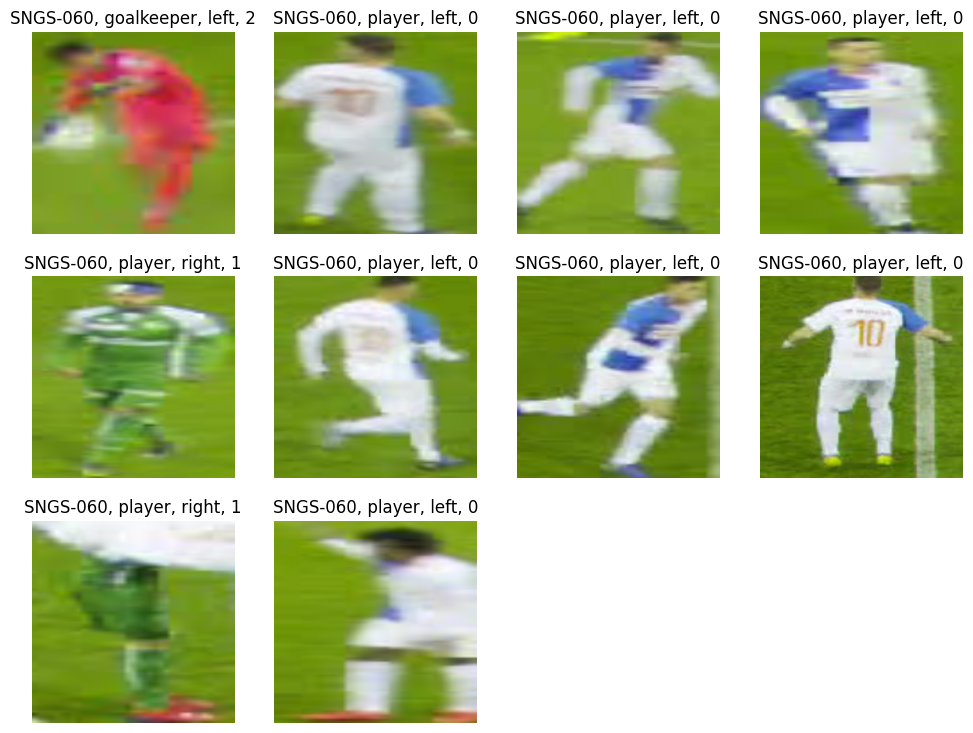

------------------------------------------------------
model input size: torch.Size([10, 3, 256, 256])
label['role_id'] size: torch.Size([10])
label['role_id']: tensor([2, 0, 1, 0, 4, 4, 1, 0, 1, 0])


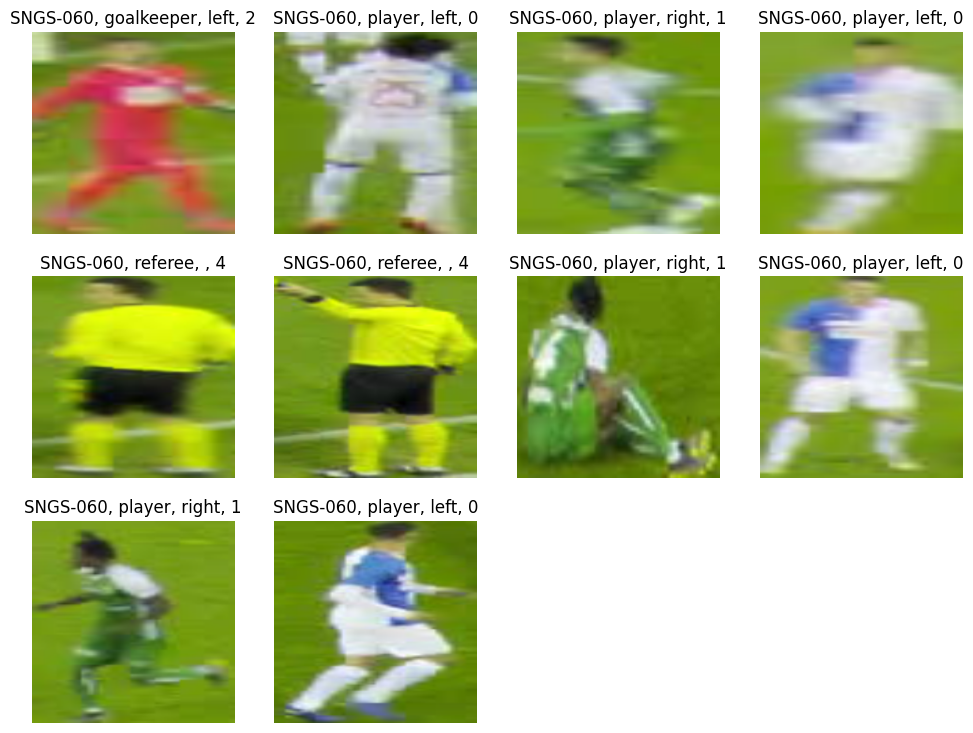

------------------------------------------------------
model input size: torch.Size([10, 3, 256, 256])
label['role_id'] size: torch.Size([10])
label['role_id']: tensor([1, 1, 4, 1, 4, 1, 1, 1, 1, 0])


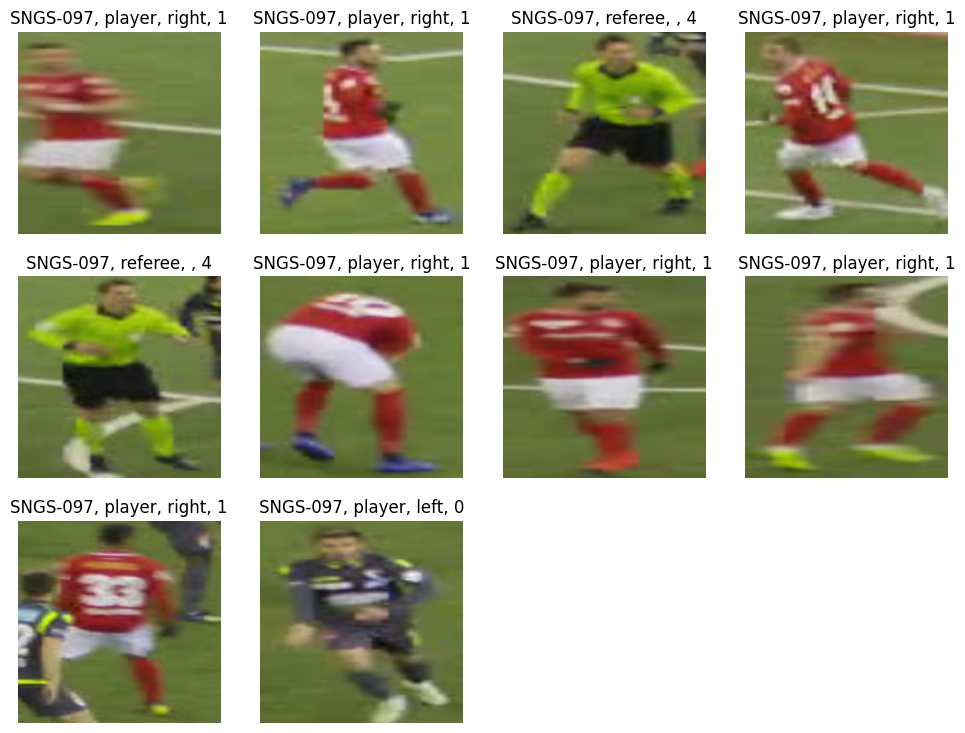

------------------------------------------------------


In [3]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader


batch_idx_limit = 3
for batch_idx, (images, labels) in enumerate(loader):
    if batch_idx == batch_idx_limit: break
    print(f"model input size: {images.shape}")
    print(f"label['role_id'] size: {labels['role_id'].shape}")
    print(f"label['role_id']: {labels['role_id']}")
    
    images_titles = []
    for batch_element_idx in range(images.shape[0]):
        batch_element_video = labels["video"][batch_element_idx]
        batch_element_role = labels["role"][batch_element_idx]
        batch_element_team = labels["team"][batch_element_idx]
        batch_element_roleId = labels["role_id"][batch_element_idx]
        
        img_title = f"{batch_element_video}, {batch_element_role}, {batch_element_team}, {batch_element_roleId}"
        images_titles.append(img_title)
    
    print_batch(images, images_titles)
    
    print("------------------------------------------------------")